In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
dataset = pd.read_csv('synthetic_umkm_data.csv')
X = dataset.iloc[:, [2, 3]].values
y = dataset.iloc[:, -1].values

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state = 0)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
df = pd.read_csv("synthetic_umkm_data.csv")

print("Dataset berhasil dibaca")

Dataset berhasil dibaca


In [ ]:
display(df.head())

,ID,Monthly_Revenue,Net_Profit_Margin (%),Burn_Rate_Ratio,Transaction_Count,Avg_Historical_Rating,Review_Text,Review_Volatility,Business_Tenure_Months,Repeat_Order_Rate (%),Digital_Adoption_Score,Peak_Hour_Latency,Location_Competitiveness,Sentiment_Score,Class
0,1,6680716,22.72,0.811,161,4.75,"Transaksi digital lancar, proses checkout tida...",0.313,105,19.40,4.24,Low,9,-0.25,Growth
1,2,5819101,4.46,0.968,104,4.21,"Harga dan kualitas seimbang, pengalaman biasa ...",0.632,95,14.87,1.27,Med,10,0.00,Growth
2,3,5236404,-10.12,1.047,102,3.51,"Pelayanan standar, masih bisa ditingkatkan.",0.470,17,21.00,3.37,Med,8,0.00,Struggling
3,4,8043552,0.04,0.969,99,4.33,"Transaksi digital lancar, proses checkout tida...",0.206,109,30.62,5.41,Low,13,-0.25,Growth
4,5,6071256,4.22,0.954,115,4.34,Selalu repeat order karena kualitasnya terjaga...,0.232,74,20.87,2.67,Low,7,0.25,Growth


In [ ]:
print("Ukuran dataset:", df.shape)


Ukuran dataset: (150000, 15)


In [ ]:
print("\nNama kolom:")
print(df.columns.tolist())


Nama kolom:
['ID', 'Monthly_Revenue', 'Net_Profit_Margin (%)', 'Burn_Rate_Ratio', 'Transaction_Count', 'Avg_Historical_Rating', 'Review_Text', 'Review_Volatility', 'Business_Tenure_Months', 'Repeat_Order_Rate (%)', 'Digital_Adoption_Score', 'Peak_Hour_Latency', 'Location_Competitiveness', 'Sentiment_Score', 'Class']


In [ ]:
print("\nInformasi dataset:")
df.info()


Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 15 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        150000 non-null  int64  
 1   Monthly_Revenue           150000 non-null  int64  
 2   Net_Profit_Margin (%)     150000 non-null  float64
 3   Burn_Rate_Ratio           150000 non-null  float64
 4   Transaction_Count         150000 non-null  int64  
 5   Avg_Historical_Rating     150000 non-null  float64
 6   Review_Text               150000 non-null  object 
 7   Review_Volatility         150000 non-null  float64
 8   Business_Tenure_Months    150000 non-null  int64  
 9   Repeat_Order_Rate (%)     150000 non-null  float64
 10  Digital_Adoption_Score    150000 non-null  float64
 11  Peak_Hour_Latency         150000 non-null  object 
 12  Location_Competitiveness  150000 non-null  int64  
 13  Sentiment_Score         

In [ ]:
print("Jumlah data kosong:")
print(df.isnull().sum())

Jumlah data kosong:
ID                          0
Monthly_Revenue             0
Net_Profit_Margin (%)       0
Burn_Rate_Ratio             0
Transaction_Count           0
Avg_Historical_Rating       0
Review_Text                 0
Review_Volatility           0
Business_Tenure_Months      0
Repeat_Order_Rate (%)       0
Digital_Adoption_Score      0
Peak_Hour_Latency           0
Location_Competitiveness    0
Sentiment_Score             0
Class                       0
dtype: int64


In [ ]:
print("\nJumlah data duplikat:")
print(df.duplicated().sum())


Jumlah data duplikat:
0


In [ ]:
print("\nJumlah ID duplikat:")
print(df["ID"].duplicated().sum())


Jumlah ID duplikat:
0


In [ ]:
display(df.describe())

,ID,Monthly_Revenue,Net_Profit_Margin (%),Burn_Rate_Ratio,Transaction_Count,Avg_Historical_Rating,Review_Volatility,Business_Tenure_Months,Repeat_Order_Rate (%),Digital_Adoption_Score,Location_Competitiveness,Sentiment_Score
count,150000.000000,1.500000e+05,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,75000.500000,8.451726e+06,1.842272,0.969885,117.766667,4.061107,0.407203,91.006840,19.980521,3.546894,8.998807,-0.018946
std,43301.414527,5.291163e+06,15.002406,0.144039,42.618493,0.521698,0.166806,51.104736,8.021928,1.670303,2.828602,0.320534
min,1.000000,1.500000e+06,-35.000000,0.437000,9.000000,1.500000,0.060000,3.000000,2.000000,1.000000,1.000000,-0.650000
25%,37500.750000,4.745884e+06,-8.430000,0.869000,86.000000,3.770000,0.278000,47.000000,14.450000,2.260000,7.000000,-0.250000
50%,75000.500000,7.245678e+06,2.160000,0.966000,117.000000,4.100000,0.405000,91.000000,19.950000,3.480000,9.000000,0.000000
75%,112500.250000,1.083026e+07,12.310000,1.067000,149.000000,4.410000,0.526000,135.000000,25.430000,4.690000,11.000000,0.000000
max,150000.000000,8.206754e+07,45.000000,1.550000,285.000000,5.000000,0.990000,179.000000,54.060000,10.000000,23.000000,0.800000


In [ ]:
import seaborn as sns

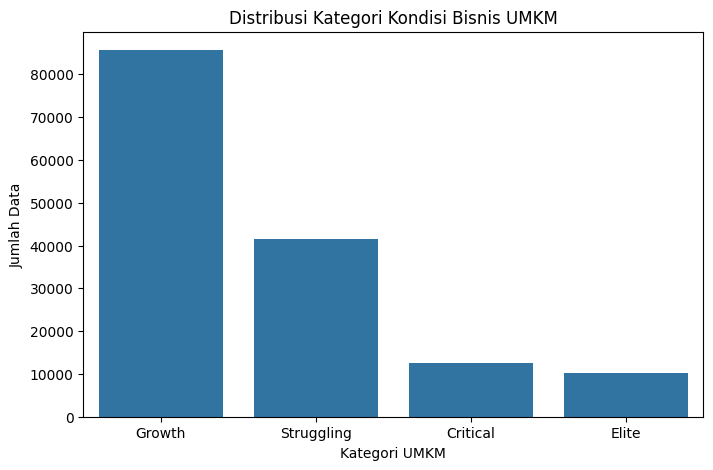

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Class",
    order=df["Class"].value_counts().index
)

plt.title("Distribusi Kategori Kondisi Bisnis UMKM")
plt.xlabel("Kategori UMKM")
plt.ylabel("Jumlah Data")

plt.show()

In [ ]:
target = "Class"

In [ ]:
kolom_dihapus = [
    "ID",
    "Review_Text",
    "Class"
]

In [ ]:
X = df.drop(columns=kolom_dihapus)

In [ ]:
y = df[target]

print("Jumlah fitur:", X.shape[1])

Jumlah fitur: 12


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 120000
Jumlah data testing: 30000


In [ ]:
categorical_features = [
    "Peak_Hour_Latency"
]

In [ ]:
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "kategori",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerik",
            "passthrough",
            numerical_features
        )
    ]
)

In [ ]:
print("Preprocessing berhasil dibuat")

Preprocessing berhasil dibuat


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

In [ ]:
model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),

        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=12,
                min_samples_leaf=5,
                random_state=42
            )
        )
    ]
)

print("Model Decision Tree berhasil dibuat")

Model Decision Tree berhasil dibuat


In [ ]:
model.fit(X_train, y_train)

print("Model berhasil dilatih")

Model berhasil dilatih


In [ ]:
y_pred = model.predict(X_test)

print("Prediksi berhasil dilakukan")

Prediksi berhasil dilakukan


In [ ]:
hasil_prediksi = pd.DataFrame({
    "Class_Aktual": y_test.iloc[:10].values,
    "Class_Prediksi": y_pred[:10]
})

display(hasil_prediksi)

,Class_Aktual,Class_Prediksi
0,Growth,Growth
1,Growth,Growth
2,Growth,Growth
3,Growth,Growth
4,Growth,Growth
5,Critical,Critical
6,Struggling,Struggling
7,Growth,Growth
8,Critical,Critical
9,Struggling,Struggling


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Model:")
print(round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Accuracy Model:
99.84 %

Classification Report:
              precision    recall  f1-score   support

    Critical       1.00      1.00      1.00      2512
       Elite       1.00      0.99      1.00      2038
      Growth       1.00      1.00      1.00     17136
  Struggling       1.00      1.00      1.00      8314

    accuracy                           1.00     30000
   macro avg       1.00      1.00      1.00     30000
weighted avg       1.00      1.00      1.00     30000



Text(70.72222222222221, 0.5, 'Aktual')

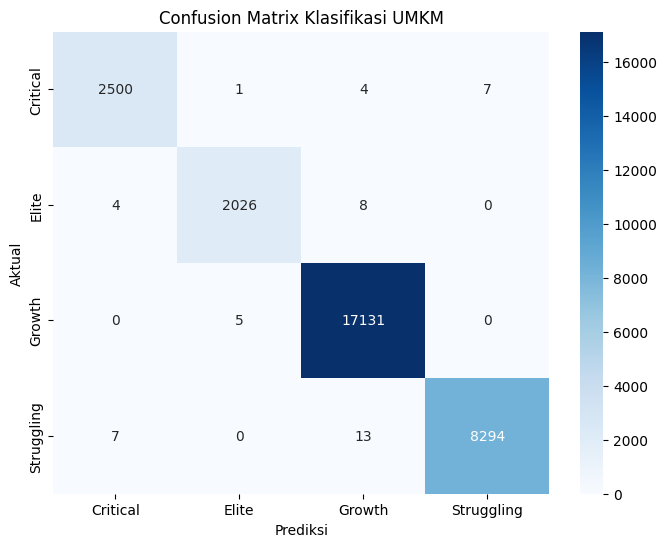

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.title("Confusion Matrix Klasifikasi UMKM")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

In [ ]:
tree_model = model.named_steps["classifier"]

In [ ]:
feature_names = (
    model.named_steps["preprocessing"]
    .get_feature_names_out()
)

In [ ]:
importance = tree_model.feature_importances_

In [ ]:
feature_importance = pd.DataFrame({
    "Fitur": feature_names,
    "Importance": importance
})

In [ ]:
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

In [ ]:
display(feature_importance.head(10))

,Fitur,Importance
4,numerik__Net_Profit_Margin (%),0.488170
5,numerik__Burn_Rate_Ratio,0.319736
7,numerik__Avg_Historical_Rating,0.094916
10,numerik__Repeat_Order_Rate (%),0.043518
0,kategori__Peak_Hour_Latency_High,0.041346
12,numerik__Location_Competitiveness,0.009591
9,numerik__Business_Tenure_Months,0.002418
11,numerik__Digital_Adoption_Score,0.000139
3,numerik__Monthly_Revenue,0.000109
13,numerik__Sentiment_Score,0.000046


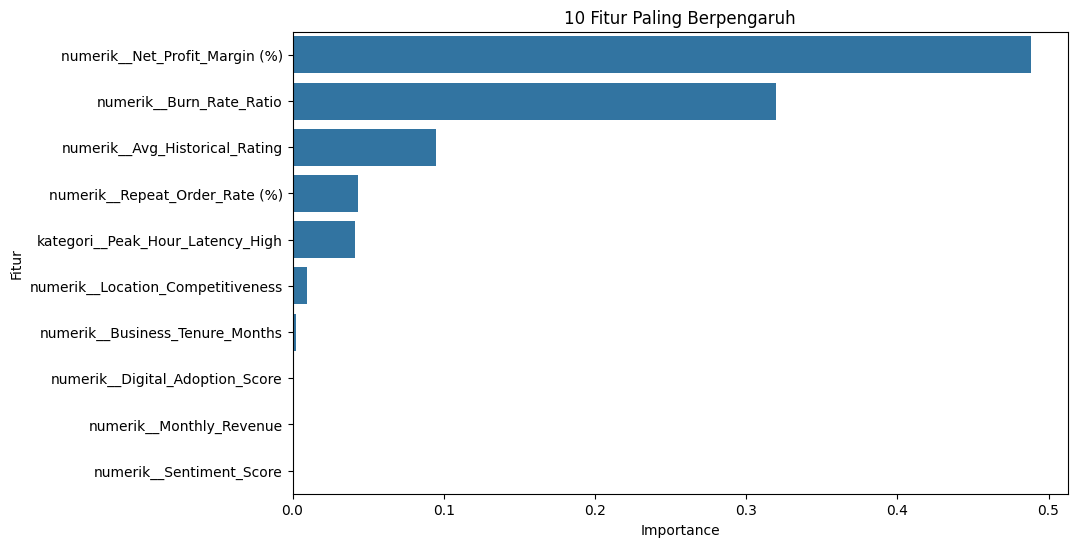

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Fitur"
)

plt.title("10 Fitur Paling Berpengaruh")
plt.show()

In [ ]:
contoh_umkm = X.iloc[[0]]

In [ ]:
prediksi_umkm = model.predict(contoh_umkm)

print("Hasil prediksi kondisi bisnis UMKM:")
print(prediksi_umkm[0])

Hasil prediksi kondisi bisnis UMKM:
Growth


In [ ]:
print("===================================")
print("HASIL PENAMBANGAN DATA UMKM")
print("===================================")

print("Jumlah data:", len(df))

print("Jumlah fitur:", X.shape[1])

print("Algoritma: Decision Tree Classifier")

print("Akurasi model:", round(accuracy * 100, 2), "%")

print("\nKategori UMKM:")
print(df["Class"].value_counts())

print("\nPenambangan data selesai")

HASIL PENAMBANGAN DATA UMKM
Jumlah data: 150000
Jumlah fitur: 12
Algoritma: Decision Tree Classifier
Akurasi model: 99.84 %

Kategori UMKM:
Class
Growth        85678
Struggling    41571
Critical      12561
Elite         10190
Name: count, dtype: int64

Penambangan data selesai
